# Simple MD to Describe Materials


## Molecular Dynamics - Things Move
- We are gods creating tiny worlds
- What do our particles represent?
- Focus on atoms in a material for now

## Solving Physical Equations of Motion
- We'll focus on Newton's Equations of motion
- What limitations have we already given ourselves?
    

- We're limiting ourselves to Newtonian Physics (obviously...)
- Ignoring quantum mechanincal effects
- Every decision in MD has consequences

## Atoms Move in a Box
- In a system of N atoms, we determine the starting positions
- We determine the box size
- What's the next limitation we've just found?

In [4]:
import numpy as np

N = 5                            # Atoms
D = 2                            # Dimensions
box_l = 100                      # Box length in angstroms

# Initial Positions
r = np.random.rand(N, D)         # Random positions between 0 and 1
r *= box_l                       # Scale positions by box length

# Print positions in a more intelligible way
print("Initial positions of atoms:")
for i in range(N):
    print(f"Atom {i+1}: x = {r[i, 0]:.2f} Å, y = {r[i, 1]:.2f} Å")

Initial positions of atoms:
Atom 1: x = 11.80 Å, y = 77.78 Å
Atom 2: x = 94.05 Å, y = 21.11 Å
Atom 3: x = 15.96 Å, y = 39.38 Å
Atom 4: x = 65.13 Å, y = 89.71 Å
Atom 5: x = 54.01 Å, y = 87.35 Å


## Atoms MOVE in a Box
- We have our atoms
- What happens with time?

$ \vec{\,v}(t + \delta t) = v(t) + \vec{\,a}\delta t $

$ \vec{\,r}(t + \delta t) = r(t) + \vec{\,v}\delta t $

## Atoms MOVE in a Box
- v(0) = 0 or set by user 
- Another decision we have to make...

In [5]:
# Plotting
from mpl_toolkits import mplot3d
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

def plot_trajectories(positions, box_l):
    num_steps, N, D = positions.shape[0] - 1, positions.shape[1], positions.shape[2]
    color = 'C0'  # Use the same color for all lines and markers

    if D == 2:
        plt.figure(figsize=(8, 8))
        for i in range(N):
            x = positions[:, i, 0]
            y = positions[:, i, 1]
            # Plot the trajectory
            plt.plot(x, y, '-', color=color)
            # Plot the initial position as an open circle
            plt.plot(x[0], y[0], 'o', markerfacecolor='none', markeredgecolor=color)
            # Plot the final position as a closed circle
            plt.plot(x[-1], y[-1], 'o', markerfacecolor=color, markeredgecolor=color)
        plt.xlabel('x')
        plt.ylabel('y')
        plt.title('Atom Trajectories')
        plt.axis('equal')
        plt.xlim(0, box_l)
        plt.ylim(0, box_l)
        # Create custom legend
        legend_elements = [
            Line2D([0], [0], color=color, lw=2, label='Path'),
            Line2D([0], [0], marker='o', color='w', markerfacecolor='none',
                   markeredgecolor=color, label='Start', markersize=8),
            Line2D([0], [0], marker='o', color=color, label='End', markersize=8)
        ]
        plt.legend(handles=legend_elements)
        plt.show()
    elif D == 3:
        fig = plt.figure(figsize=(8, 8))
        ax = fig.add_subplot(111, projection='3d')
        for i in range(N):
            x = positions[:, i, 0]
            y = positions[:, i, 1]
            z = positions[:, i, 2]
            # Plot the trajectory
            ax.plot(x, y, z, '-', color=color)
            # Plot the initial position as an open circle
            ax.plot([x[0]], [y[0]], [z[0]], 'o', markerfacecolor='none', markeredgecolor=color)
            # Plot the final position as a closed circle
            ax.plot([x[-1]], [y[-1]], [z[-1]], 'o', markerfacecolor=color, markeredgecolor=color)
        ax.set_xlabel('x')
        ax.set_ylabel('y')
        ax.set_zlabel('z')
        plt.title('Atom Trajectories')
        ax.set_xlim(0, box_l)
        ax.set_ylim(0, box_l)
        ax.set_zlim(0, box_l)
        # Create custom legend
        legend_elements = [
            Line2D([0], [0], color=color, lw=2, label='Path'),
            Line2D([0], [0], marker='o', color='w', markerfacecolor='none',
                   markeredgecolor=color, label='Start', markersize=8),
            Line2D([0], [0], marker='o', color=color, label='End', markersize=8)
        ]
        ax.legend(handles=legend_elements)
        plt.show()
    else:
        print("Dimension D must be 2 or 3.")
        
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from itertools import combinations, product

def create_trajectory_gif(positions, tp, box_l, sigma_matrix, filename='trajectory.gif'):
    num_frames, N, D = positions.shape
    unique_types = np.unique(tp)
    num_types = len(unique_types)
    
    # Create a color map for the types
    cmap = plt.get_cmap('tab10')
    colors_list = [cmap(i % 10) for i in range(num_types)]
    type_to_color = {t: colors_list[i] for i, t in enumerate(unique_types)}
    
    # Create an array of colors for each particle
    particle_colors = np.array([type_to_color[tp[i]] for i in range(N)])
    
    # Extract sigma values from the diagonal of sigma_matrix based on particle types
    sigma_values = sigma_matrix[tp, tp]
    # Scale sigma values for marker sizes
    scaling_factor = 100  # Adjust this factor for visual clarity
    marker_sizes = sigma_values * scaling_factor
    
    # Initialize figure and axes
    fig = plt.figure(figsize=(8, 8))
    
    if D == 2:
        # Adjust figure to make room for the progress bar
        plt.subplots_adjust(bottom=0.15)
        
        ax = fig.add_subplot(111)
        # Set up plot limits
        ax.set_xlim(0, box_l)
        ax.set_ylim(0, box_l)
        ax.set_aspect('equal')
        # Remove labels
        ax.axis('off')
        
        # Draw black boundaries
        rect = plt.Rectangle((0, 0), box_l, box_l,
                             linewidth=2, edgecolor='black', facecolor='none')
        ax.add_patch(rect)
        
        # Initialize scatter plot with initial positions
        x = positions[0, :, 0]
        y = positions[0, :, 1]
        scatter = ax.scatter(x, y, s=marker_sizes, facecolors=particle_colors)
        
        # Add progress bar axes
        ax_progress = fig.add_axes([0.1, 0.05, 0.8, 0.02])  # [left, bottom, width, height]
        ax_progress.set_xlim(0, num_frames)
        ax_progress.set_ylim(0, 1)
        ax_progress.axis('off')
        # Initialize progress bar
        progress_bar = plt.Rectangle((0, 0), 0, 1, color='black')
        ax_progress.add_patch(progress_bar)
        
        def init():
            # Optionally, reset positions to NaNs to start with an empty plot
            scatter.set_offsets(np.c_[np.full(N, np.nan), np.full(N, np.nan)])
            progress_bar.set_width(0)
            return scatter, progress_bar
        
        def update(frame):
            x = positions[frame, :, 0]
            y = positions[frame, :, 1]
            coords = np.column_stack((x, y))
            scatter.set_offsets(coords)
            # No need to update sizes and colors as they are constant
            progress_bar.set_width(frame + 1)
            return scatter, progress_bar
        
    elif D == 3:
        # Adjust figure to make room for the progress bar
        plt.subplots_adjust(bottom=0.15)
        
        ax = fig.add_subplot(111, projection='3d')
        # Set up plot limits
        ax.set_xlim(0, box_l)
        ax.set_ylim(0, box_l)
        ax.set_zlim(0, box_l)
        # Remove labels
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_zticks([])
        
        # Draw black boundaries (cube edges)
        r = [0, box_l]
        for s_e in combinations(np.array(list(product(r, r, r))), 2):
            s, e = s_e
            if np.sum(np.abs(s - e)) == r[1] - r[0]:
                ax.plot3D(*zip(s, e), color='black', linewidth=1)
        
        # Initialize scatter plot with initial positions
        x = positions[0, :, 0]
        y = positions[0, :, 1]
        z = positions[0, :, 2]
        scatter = ax.scatter(x, y, z, s=marker_sizes, facecolors=particle_colors)
        
        # Add progress bar axes
        ax_progress = fig.add_axes([0.1, 0.05, 0.8, 0.02])  # [left, bottom, width, height]
        ax_progress.set_xlim(0, num_frames)
        ax_progress.set_ylim(0, 1)
        ax_progress.axis('off')
        # Initialize progress bar
        progress_bar = plt.Rectangle((0, 0), 0, 1, color='black')
        ax_progress.add_patch(progress_bar)
        
        def init():
            # Optionally, reset positions to NaNs to start with an empty plot
            scatter._offsets3d = (np.full(N, np.nan), np.full(N, np.nan), np.full(N, np.nan))
            progress_bar.set_width(0)
            return scatter, progress_bar
        
        def update(frame):
            x = positions[frame, :, 0]
            y = positions[frame, :, 1]
            z = positions[frame, :, 2]
            scatter._offsets3d = (x, y, z)
            # No need to update sizes and colors as they are constant
            progress_bar.set_width(frame + 1)
            return scatter, progress_bar
    else:
        print("Dimension D must be 2 or 3.")
        return
    
    ani = animation.FuncAnimation(fig, update, frames=num_frames,
                                  init_func=init, blit=False, interval=50)
    
    # Save the animation as GIF using Pillow writer
    ani.save(filename, writer='pillow')
    
    plt.close(fig)



In [6]:
dt = 0.01                        # Time step in femtoseconds
num_steps = 100                  # Number of simulation steps

# Initial Velocity
v_0 = 10 * (np.random.rand(N, D) ) #- 0.5)
v = v_0

# Equation of motion
def update(r, v, dt):
    r_t = r + v * dt
    return r_t

# Simulation
positions = np.zeros((num_steps + 1, N, D))
positions[0] = r.copy()

for i in range(num_steps):
    r = update(r, v, dt)
    positions[i + 1] = r.copy()

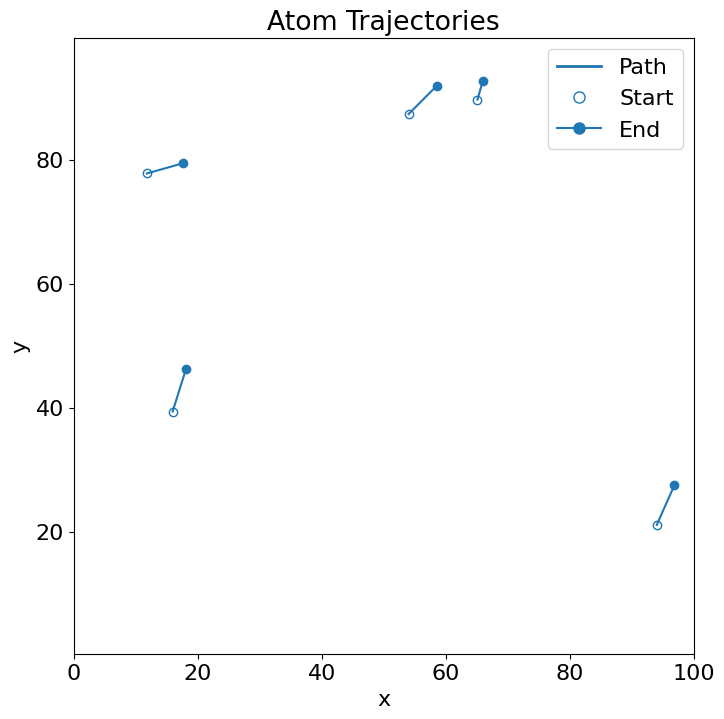

In [ ]:
plot_trajectories(positions, box_l)

### Assumptions
- velocity is positive, showing a drift of all particles in the same direction. 
- We've chosen a timestep arbitrarily, what are the consequeunces here? 
- Our particles are non-interacting. 
- We have neglected boundary conditions, so it possible for our particles to leave their box. 
- We have a constant velocity.

## Let's Consider the Box
- We have two options for when an atom reaches the wall
    1. A hard boundary that reflects the atoms momentum
    2. A periodic boundary, which translates the atom to the opposite wall
![Periodic Boundary Conditions](PBC.png)


## Atom-Atom Interactions
- Sometimes called 'pair-potentials'
- Describes the force an atom feels as a function of distance
- There are well defined 'forms', but we can choose our own.

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Define the Lennard-Jones potential function with cutoff
def lennard_jones_potential(r, epsilon, sigma, r_c):
    V = 4 * epsilon * ((sigma / r)**12 - (sigma / r)**6)
    V[r >= r_c] = 0
    return V

# Parameters
epsilon = 1.0         # Depth of the potential well
sigma = 1.0           # Finite distance where the inter-particle potential is zero
r_c = 2.5 * sigma     # Cutoff distance

# Distance array avoiding r=0 to prevent division by zero
r = np.linspace(0.8 * sigma, 3 * sigma, 500)
V = lennard_jones_potential(r, epsilon, sigma, r_c)

# Calculate the minimum of the potential
r_min = 2**(1/6) * sigma   # Position of the potential minimum
V_min = lennard_jones_potential(np.array([r_min]), epsilon, sigma, r_c)[0]

# Create the plot
plt.figure(figsize=(12, 8))

# Increase font sizes
plt.rcParams.update({'font.size': 16})

# Plot the Lennard-Jones potential
plt.plot(r, V, label='Lennard-Jones Potential', color='C0', linewidth=3)

# Annotate sigma (V = 0)
plt.scatter([sigma], [0], color='C1', s=150, zorder=5)
plt.annotate(r'$\sigma$', xy=(sigma, 0), xytext=(sigma + 0.1 * sigma, 0.5 * epsilon),
             arrowprops=dict(arrowstyle='->', color='C1', linewidth=2), color='C1')

# Annotate epsilon (minimum potential)
plt.scatter([r_min], [V_min], color='C2', s=150, zorder=5)
plt.annotate(r'$-\epsilon$', xy=(r_min, V_min), xytext=(r_min + 0.1 * sigma, V_min - 0.5 * epsilon + 0.2),
             arrowprops=dict(arrowstyle='->', color='C2', linewidth=2), color='C2')

# Draw the cutoff line at r_c
plt.axvline(r_c, color='C3', linestyle='--', linewidth=2, label=r'Cutoff Distance $r_c$')

# Labels and title
plt.xlabel('Interatomic Distance $r$ (Å)', fontsize=18)
plt.ylabel('Potential Energy $V(r)$ (kBT)', fontsize=18)
plt.title('Lennard-Jones Potential with Cutoff', fontsize=20)

# Legend
plt.legend(fontsize=16, loc='upper right', framealpha=1)

# Grid and limits
plt.xlim(0.8 * sigma, 3 * sigma)
plt.ylim(-1.5 * epsilon, 1.5 * epsilon)

# Display the equation including the cutoff condition
equation_text1 = r'$V(r) = 4\epsilon \left[ \left( \dfrac{\sigma}{r} \right)^{12} - \left( \dfrac{\sigma}{r} \right)^6 \right], \quad r < r_c$'
equation_text2 = r'$V(r) = 0, \quad r \geq r_c$'

plt.figtext(0.5, 0.3, equation_text1, ha='center', fontsize=20)
plt.figtext(0.415, 0.22, equation_text2, ha='center', fontsize=20)

# Show the plot
plt.savefig('LJ.png')
plt.close()


![LJ](LJ.png)

## Atom-Atom Interactions
- Sometimes called 'pair-potentials'
- Describes the force an atom feels as a function of distance
- There are well defined 'forms', but we can choose our own.
- Our job is to turn the potential energy into kinetic energy (F = ma)
- $ F(r) = -\dfrac{dV}{dr} = 24\epsilon \left[ 2\left( \dfrac{\sigma}{r} \right)^{13} - \left( \dfrac{\sigma}{r} \right)^7 \right] 
$

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# Define the Lennard-Jones potential function with cutoff
def lennard_jones_potential(r, epsilon, sigma, r_c):
    V = 4 * epsilon * ((sigma / r)**12 - (sigma / r)**6)
    V[r >= r_c] = 0
    return V

# Define the Lennard-Jones force function with cutoff
def lennard_jones_force(r, epsilon, sigma, r_c):
    F = 24 * epsilon * ((2 * (sigma / r)**13) - (sigma / r)**7)
    F[r >= r_c] = 0
    return F

# Parameters
epsilon = 1.0         # Depth of the potential well
sigma = 1.0           # Distance where the potential is zero
r_c = 1.75 * sigma     # Cutoff distance

# Distance array avoiding r=0 to prevent division by zero
r = np.linspace(0.8 * sigma, 3 * sigma, 500)
V = lennard_jones_potential(r, epsilon, sigma, r_c)
F = lennard_jones_force(r, epsilon, sigma, r_c)

# Calculate the minimum of the potential
r_min = 2**(1/6) * sigma   # Position of the potential minimum
V_min = lennard_jones_potential(np.array([r_min]), epsilon, sigma, r_c)[0]

# Create the plot
plt.figure(figsize=(12, 8))

# Increase font sizes
plt.rcParams.update({'font.size': 16})

# Plot the Lennard-Jones potential
plt.plot(r, V, label='Potential Energy $V(r)$', color='C0', linewidth=3)

# Plot the Lennard-Jones force
plt.plot(r, F, label='Force $F(r)$', color='C1', linewidth=3)

# Annotate sigma (V = 0)
plt.scatter([sigma], [0], color='C2', s=150, zorder=5)
plt.annotate(r'$\sigma$', xy=(sigma, 0), xytext=(sigma + 0.1 * sigma, 0.5 * epsilon),
             arrowprops=dict(arrowstyle='->', color='C2', linewidth=2), color='C2')

# Annotate epsilon (minimum potential)
plt.scatter([r_min], [V_min], color='C3', s=150, zorder=5)
plt.annotate(r'$-\epsilon$', xy=(r_min, V_min), xytext=(r_min + 0.1 * sigma, V_min - 0.5 * epsilon + 0.2),
             arrowprops=dict(arrowstyle='->', color='C3', linewidth=2), color='C3')

# Draw the cutoff line at r_c
plt.axvline(r_c, color='C4', linestyle='--', linewidth=2, label=r'Cutoff Distance $r_c$')

# Labels and title
plt.xlabel('Interatomic Distance $r$ (Å)', fontsize=18)
plt.ylabel('Potential Energy $V(r)$ and Force $F(r)$', fontsize=18)
plt.title('Lennard-Jones Potential and Force with Cutoff', fontsize=20)

# Legend
plt.legend(fontsize=16, loc='upper right', framealpha=1)

# Grid and limits
plt.xlim(0.8 * sigma, 3 * sigma)
plt.ylim(np.min(F)-1, 4 * epsilon)

# Show the plot
plt.savefig('LJ_w_force.png')
plt.close()

![LJ_w_force](LJ_w_force.png)

## Discussion
### Why would we want to use a cutoff?
### Why do we like the Lennard Jones potential?

In [10]:
def LJpot(r, i, sigma_matrix, epsilon_matrix, tp):
    n = len(r)
    type_i = tp[i]
    # Exclude self-interaction
    indices = np.arange(n) != i
    drv = r[indices] - r[i]  # Relative positions
    dr = np.linalg.norm(drv, axis=1)  # Distances
    types_j = tp[indices]
    
    # Get sigma and epsilon values for interactions between type_i and types_j
    sig = sigma_matrix[type_i, types_j]
    eps = epsilon_matrix[type_i, types_j]
    
    # Compute potential
    r6 = (sig / dr) ** 6
    r12 = r6 ** 2
    LJP = 4.0 * eps * (r12 - r6)
    return np.sum(LJP)

def dLJp(r, i, sigma_matrix, epsilon_matrix, tp):
    n = len(r)
    type_i = tp[i]
    # Exclude self-interaction
    indices = np.arange(n) != i
    drv = r[indices] - r[i]  # Relative positions
    dr = np.linalg.norm(drv, axis=1)  # Distances
    types_j = tp[indices]
    
    # Get sigma and epsilon values
    sig = sigma_matrix[type_i, types_j]
    eps = epsilon_matrix[type_i, types_j]
    
    # Calculate force components
    r_vec = drv / dr[:, np.newaxis]  # Unit vectors
    r14 = (sig / dr) ** 14
    r8 = (sig / dr) ** 8
    
    force_scalar = 24 * eps * (2 * r14 - r8)
    force_vectors = (force_scalar[:, np.newaxis]) * r_vec
    total_force = np.sum(force_vectors, axis=0)
    return total_force

def updatev(r, v, dt, sigma_matrix, epsilon_matrix, tp, masses):
    n = len(r)
    F = np.zeros_like(r)
    for i in range(n):
        # Calculate force on particle i
        F[i] = -dLJp(r, i, sigma_matrix, epsilon_matrix, tp)
    a = F / masses[:, np.newaxis]  # Acceleration
    newv = v + dt * a
    return newv

def calculate_kinetic_energy(v, masses):
    # v: velocities array of shape (N, D)
    # masses: array of masses of length N
    kinetic_energy = 0.5 * masses * np.sum(v**2, axis=1)
    total_kinetic_energy = np.sum(kinetic_energy)
    return total_kinetic_energy

def calculate_potential_energy(r, sigma_matrix, epsilon_matrix, tp):
    N = len(r)
    potential_energy = 0.0
    for i in range(N - 1):
        type_i = tp[i]
        for j in range(i + 1, N):
            type_j = tp[j]
            sigma_ij = sigma_matrix[type_i, type_j]
            epsilon_ij = epsilon_matrix[type_i, type_j]
            rij_vector = r[j] - r[i]
            rij = np.linalg.norm(rij_vector)
            if rij == 0:
                continue  # Avoid division by zero
            # Calculate Lennard-Jones potential
            sr6 = (sigma_ij / rij) ** 6
            sr12 = sr6 ** 2
            v_ij = 4 * epsilon_ij * (sr12 - sr6)
            potential_energy += v_ij
    return potential_energy



In [11]:
sigma_00 = 1.0
sigma_01 = 1.2
sigma_02 = 1.1
sigma_11 = 1.0
sigma_12 = 1.3
sigma_22 = 1.0

sigma_matrix = np.array([
    [sigma_00, sigma_01, sigma_02],
    [sigma_01, sigma_11, sigma_12],
    [sigma_02, sigma_12, sigma_22]
])

epsilon_00 = 1.0
epsilon_01 = 0.8
epsilon_02 = 0.9
epsilon_11 = 1.0
epsilon_12 = 0.7
epsilon_22 = 1.0

epsilon_matrix = np.array([
    [epsilon_00, epsilon_01, epsilon_02],
    [epsilon_01, epsilon_11, epsilon_12],
    [epsilon_02, epsilon_12, epsilon_22]
])

In [12]:
import numpy as np

N = 20  # Total number of particles
D = 2  # Dimensions
box_l = 100
M = 1    # Number of particle types
num_steps = 100
dt = 0.0001  # Time step


tp = np.random.randint(0, M, size=N) # Assign random types to each particle (types are 0, 1, ..., M-1)
masses = np.ones(N)  # Assuming all particles have mass = 1

# Initialize positions
r = np.random.rand(N, D) * box_l

# Initialize velocities
v_0 = 1 * (np.random.rand(N, D) - 0.5)
v = v_0

# Run Simulation

positions = np.zeros((num_steps + 1, N, D))
positions[0] = r.copy()

for step in range(num_steps):
    for extrastep in range(500):
        v = updatev(r, v, dt, sigma_matrix, epsilon_matrix, tp, masses)
        r = r + v * dt  # Update positions
        r = r%box_l # Periodic Boundary Condition
    positions[step + 1] = r.copy()

create_trajectory_gif(positions, tp, box_l,sigma_matrix, filename=f'trajectory.gif')

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation parameters
iterations = 100
timestep = 0.02
mass = [1, 1]  # Masses of the particles

# Initial conditions for Verlet integration
positions_verlet = np.array([-2.0, 2.0])
velocities_verlet = np.array([0.0, 0.0])
forces_verlet = np.array([0.0, 0.0])

# Initial conditions for Euler integration
positions_euler = np.array([-2.0, 2.0])
velocities_euler = np.array([0.0, 0.0])
forces_euler = np.array([0.0, 0.0])

# Arrays to save positions and energies over time
save_positions_verlet = []
save_positions_euler = []

kinetic_energy_verlet = []
potential_energy_verlet = []
total_energy_verlet = []

kinetic_energy_euler = []
potential_energy_euler = []
total_energy_euler = []

def compute_forces(positions):
    """
    Compute the forces on each particle based on their positions.
    """
    num_particles = len(positions)
    forces = np.zeros(num_particles)
    k = 10.0  # Spring constant
    equilibrium_distance = 5.0  # Equilibrium distance

    for j in range(num_particles):
        for k_index in range(num_particles):
            if j == k_index:
                continue
            distance = positions[j] - positions[k_index]
            abs_distance = abs(distance)
            sign = distance / abs_distance if abs_distance != 0 else 0
            # Spring-like force: F = -k * (|distance| - equilibrium_distance) * sign
            forces[j] += -k * (abs_distance - equilibrium_distance) * sign

    return forces

def compute_potential_energy(positions):
    """
    Compute the total potential energy of the system.
    """
    num_particles = len(positions)
    potential_energy = 0.0
    k = 10.0  # Spring constant
    equilibrium_distance = 5.0  # Equilibrium distance

    for j in range(num_particles):
        for k_index in range(j + 1, num_particles):
            distance = positions[j] - positions[k_index]
            abs_distance = abs(distance)
            # Potential energy: U = 0.5 * k * (|distance| - equilibrium_distance)^2
            potential_energy += 0.5 * k * (abs_distance - equilibrium_distance) ** 2

    return potential_energy

# Main simulation loop
for i in range(iterations):
    # Save current positions
    save_positions_verlet.append(positions_verlet.copy())
    save_positions_euler.append(positions_euler.copy())

    # Compute potential energies
    pe_verlet = compute_potential_energy(positions_verlet)
    pe_euler = compute_potential_energy(positions_euler)
    potential_energy_verlet.append(pe_verlet)
    potential_energy_euler.append(pe_euler)

    # Compute kinetic energies
    ke_verlet = 0.5 * np.sum(mass * velocities_verlet ** 2)
    ke_euler = 0.5 * np.sum(mass * velocities_euler ** 2)
    kinetic_energy_verlet.append(ke_verlet)
    kinetic_energy_euler.append(ke_euler)

    # Compute total energies
    total_energy_verlet.append(ke_verlet + pe_verlet)
    total_energy_euler.append(ke_euler + pe_euler)

    # Verlet integration
    # Update positions
    new_positions_verlet = positions_verlet + velocities_verlet * timestep + (forces_verlet / (2 * np.array(mass))) * (timestep ** 2)

    # Compute new forces
    new_forces_verlet = compute_forces(new_positions_verlet)

    # Update velocities
    velocities_verlet += (forces_verlet + new_forces_verlet) * (timestep / (2 * np.array(mass)))

    # Apply reflective boundaries
    for j in range(len(new_positions_verlet)):
        if new_positions_verlet[j] < -10 or new_positions_verlet[j] > 10:
            velocities_verlet[j] *= -1  # Reverse velocity
            new_positions_verlet[j] = np.clip(new_positions_verlet[j], -10, 10)

    # Update positions and forces
    positions_verlet = new_positions_verlet
    forces_verlet = new_forces_verlet

    # Euler integration
    # Compute forces
    forces_euler = compute_forces(positions_euler)

    # Update velocities
    velocities_euler += (forces_euler / np.array(mass)) * timestep

    # Update positions
    positions_euler += velocities_euler * timestep

    # Apply reflective boundaries
    for j in range(len(positions_euler)):
        if positions_euler[j] < -10 or positions_euler[j] > 10:
            velocities_euler[j] *= -1  # Reverse velocity
            positions_euler[j] = np.clip(positions_euler[j], -10, 10)

# Time array for plotting
time_array = np.arange(iterations) * timestep

# Plot the total energy for both methods
plt.figure(figsize=(12, 6))
plt.plot(time_array, total_energy_verlet, label='Total Energy (Verlet)', color='blue')
plt.plot(time_array, total_energy_euler, label='Total Energy (Euler)', color='red')
plt.xlabel('Time')
plt.ylabel('Total Energy')
plt.title('Total Energy vs. Time')
plt.legend(framealpha=1)
plt.grid(True)
plt.savefig('verlet_v_euler.png')
plt.close()

#Adapted from https://plainenglish.io/blog/molecular-dynamics-velocity-verlet-integration-with-python-5ae66b63a8fd

## The Timestep Dictates Accuracy

In a closed system, the total energy should be conserved (stay flat). Different algorithms can be used to determine each particle's next position

![verlet_v_euler](verlet_v_euler.png)

In [13]:
import numpy as np

N = 5  # Total number of particles
D = 2  # Dimensions
box_l = 50
M = 1    # Number of particle types
num_steps = 1000
dt = 0.01  # Time step


tp = np.random.randint(0, M, size=N) # Assign random types to each particle (types are 0, 1, ..., M-1)
masses = np.ones(N)  # Assuming all particles have mass = 1

# Initialize positions
r = np.random.rand(N, D) * box_l

# Initialize velocities
v_0 = 1 * (np.random.rand(N, D) - 0.5)
v = v_0

# Run Simulation
plt.figure(figsize=(12, 6))
for dt in [0.0001,0.0002,0.001,0.002]:

    positions = np.zeros((num_steps + 1, N, D))
    positions[0] = r.copy()
    kinetic_energies = np.zeros(num_steps + 1)
    potential_energies = np.zeros(num_steps + 1)
    total_energies = np.zeros(num_steps + 1)

    for step in range(num_steps):
        v = updatev(r, v, dt, sigma_matrix, epsilon_matrix, tp, masses)
        r = r + v * dt  # Update positions
        r = r%box_l # Periodic Boundary Condition
        positions[step + 1] = r.copy()
        kinetic_energies[step + 1] = calculate_kinetic_energy(v, masses)
        potential_energies[step + 1] = calculate_potential_energy(r, sigma_matrix, epsilon_matrix, tp)
        total_energies[step + 1] = kinetic_energies[step + 1] + potential_energies[step + 1]


    total_energies = np.asarray(total_energies)
    plt.plot(range(num_steps), np.abs(total_energies[1] - total_energies[1:]), label=f'timestep = {dt}')
plt.xlabel('Timestep')
plt.ylabel('$\delta E$')
plt.legend()
plt.savefig('Error_timesteps.png')
plt.close()
#create_trajectory_gif(positions, tp, box_l,sigma_matrix, filename=f'trajectory.gif')

* They introduce a small amount of error with every step.
* This is called **discretization error**, and it builds up over time.
* There's a trade-off between accuracy and computational speed.
* A **smaller timestep** ($dt$) reduces the error but requires more computation time.
![Error](Error_timesteps.png)

## Equipartition Theorem and Temperature

The equipartition theorem states that, for a system in thermal equilibrium, the average kinetic energy of each particle is proportional to the temperature. Specifically, for each degree of freedom, the kinetic energy is given by:

$
\langle E_{\text{kin}} \rangle = \frac{1}{2} k_B T
$

Where:
- $ \langle E_{\text{kin}} \rangle $ is the average kinetic energy,
- $ k_B $ is the Boltzmann constant,
- $ T $ is the temperature in Kelvin.

For a system of \( N \) particles with \( d \) degrees of freedom, the total kinetic energy is related to the temperature by:

$
E_{\text{kin}} = \frac{N d}{2} k_B T
$

We can calculate the temperature of the system using the total kinetic energy.


In [18]:
import numpy as np

# Constants
k_B = 1.380649e-23  # Boltzmann constant in J/K
#k_B = 1
# Function to calculate temperature using equipartition theorem
def calculate_temperature(velocities, masses):
    # Ensure velocities and masses are NumPy arrays
    velocities = np.array(velocities)
    masses = np.array(masses)
    N = len(velocities)
    # Calculate the kinetic energy for each particle
    kinetic_energy = 0.5 * np.sum(masses * velocities**2) / N
    
    # Calculate temperature: total kinetic energy = (3/2) Nk_B T
    temperature = (2 * kinetic_energy) / (3 * len(masses) * k_B)  # 3 degrees of freedom for 3D system
    return temperature

# Assuming velocities_euler and masses are defined, calculate temperature for the system
temperature = calculate_temperature(velocities_verlet, mass)

# Display the result
print(f"Temperature of the system: {temperature:.2f} K")


Temperature of the system: 15019503212905243869184.00 K


## Tasks

Exercise:

Let's design an initial configuration where nothing happens.

Workshop:

https://colab.research.google.com/drive/1rkW6sEzNF1HIWEuhih9uvpIiyqPm0f0I?usp=sharing

Reading:

https://www.ncbi.nlm.nih.gov/pmc/articles/PMC6884151/#S51

https://arxiv.org/pdf/1211.4440

https://www.eng.uc.edu/~beaucag/Classes/AdvancedMaterialsThermodynamics/Books/%5BComputational%20science%20(San%20Diego,%20Calif.)%5D%20Daan%20Frenkel_%20Berend%20Smit%20-%20Understanding%20molecular%20simulation%20_%20from%20algorithms%20to%20applications%20(2002,%20Academic%20Press%20)%20-%20libgen.lc.pdf

(page 1 - 17)
